# 04 — Models, evaluation and explainability (steps 4–6)

Run `python scripts/train_models.py`, `python scripts/evaluate_models.py` and `python scripts/explain_models.py`
first. This notebook only shows their outputs (`reports/tables`, `reports/figures`); every number is computed
there. Summary: [`docs/results.md`](../docs/results.md).

In [1]:
import pandas as pd
from IPython.display import Image, display
from hidden_risk.config import REPORT_FIGURES, REPORT_TABLES

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
t = lambda name: pd.read_csv(REPORT_TABLES / name)

## Step 4 — cross-validation on 2005–2014 and model choice

In [2]:
cv = t("step4_cv_results.csv")
display(t("step4_selected_models.csv"))
cv[["feature_set", "algorithm", "strategy", "outcome", "cv_pr_auc", "cv_pr_auc_sd", "cv_roc_auc", "cv_brier"]]

,feature_set,algorithm,strategy,cv_pr_auc,cv_roc_auc
0,demographics,hgb,none,0.058,0.589
1,phq8,lr,none,0.294,0.898
2,phq9,lr,none,0.386,0.926
3,routine,hgb,none,0.149,0.769
4,routine_phq8,lr,none,0.314,0.902
5,routine_phq9,hgb,none,0.413,0.929


,feature_set,algorithm,strategy,outcome,cv_pr_auc,cv_pr_auc_sd,cv_roc_auc,cv_brier
0,demographics,lr,none,si,0.054,0.005,0.572,0.036
1,demographics,lr,balanced,si,0.048,0.005,0.552,0.390
2,demographics,lr,smote,si,0.054,0.005,0.573,0.244
3,demographics,hgb,none,si,0.058,0.007,0.589,0.036
4,demographics,hgb,balanced,si,0.059,0.008,0.589,0.234
5,demographics,hgb,smote,si,0.055,0.005,0.582,0.169
6,routine,lr,none,si,0.145,0.018,0.767,0.034
7,routine,lr,balanced,si,0.147,0.022,0.768,0.190
8,routine,lr,smote,si,0.146,0.019,0.764,0.196
9,routine,hgb,none,si,0.149,0.025,0.769,0.034


## Step 5 — test set 2015–2018

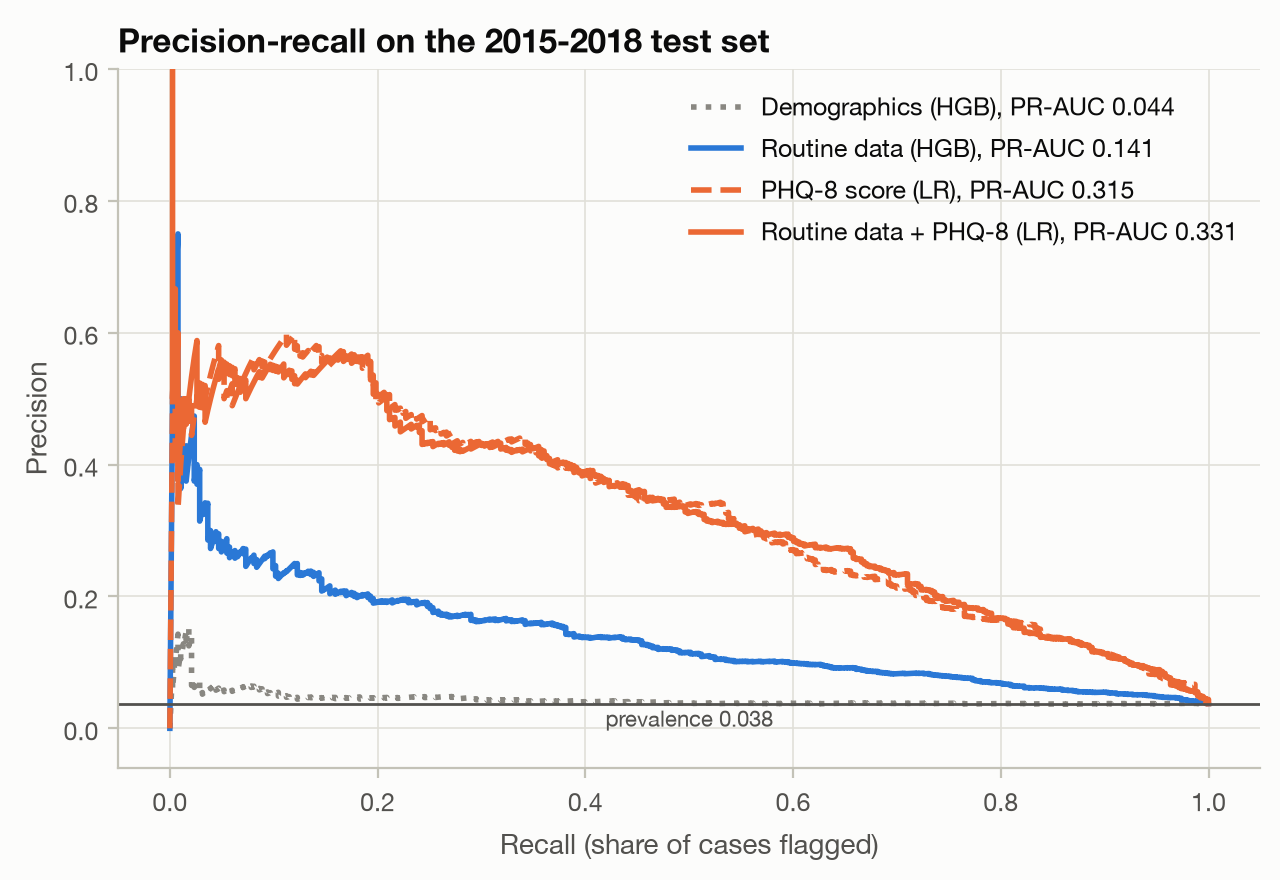

,feature_set,algorithm,strategy,selected,pr_auc,pr_auc_ci_low,pr_auc_ci_high,roc_auc,brier,calibration_slope,recall_top5,precision_top5
0,demographics,lr,none,False,0.041,0.036,0.048,0.514,0.036,0.293,0.063,0.047
1,demographics,lr,balanced,False,0.038,0.033,0.046,0.484,0.329,-0.015,0.047,0.035
2,demographics,lr,smote,False,0.041,0.036,0.048,0.512,0.247,0.284,0.063,0.047
3,demographics,hgb,none,True,0.044,0.037,0.053,0.517,0.036,0.272,0.084,0.063
4,demographics,hgb,balanced,False,0.044,0.037,0.054,0.513,0.237,0.129,0.073,0.055
5,demographics,hgb,smote,False,0.040,0.035,0.048,0.507,0.174,0.037,0.063,0.047
6,routine,lr,none,False,0.139,0.115,0.172,0.772,0.034,1.025,0.251,0.188
7,routine,lr,balanced,False,0.141,0.117,0.175,0.773,0.187,0.956,0.251,0.188
8,routine,lr,smote,False,0.137,0.113,0.169,0.773,0.192,1.025,0.245,0.184
9,routine,hgb,none,True,0.141,0.116,0.174,0.767,0.034,0.950,0.248,0.186


In [3]:
m = t("step5_test_metrics.csv")
display(Image(REPORT_FIGURES / "09_pr_curves.png", width=600))
m[["feature_set", "algorithm", "strategy", "selected", "pr_auc", "pr_auc_ci_low", "pr_auc_ci_high", "roc_auc",
   "brier", "calibration_slope", "recall_top5", "precision_top5"]]

### Hypotheses H1–H4 (paired bootstrap, 2,000 resamples)

In [4]:
t("step5_hypotheses.csv")

,hypothesis,comparison,metric,estimate,ci_low,ci_high,criterion,supported
0,H1,routine (hgb) PR-AUC - 2 x prevalence,pr_auc,0.066,4.390e-02,0.098,CI lower bound > 0,True
1,H1,routine - demographics,pr_auc,0.097,7.490e-02,0.128,CI of difference > 0,True
2,H2,routine + PHQ-8 - PHQ-8 (leakage-free),pr_auc,0.015,-4.000e-04,0.032,CI of difference > 0,False
3,H2,routine + PHQ-9 - PHQ-9 (as registered; PHQ-9 contains the outcome item),pr_auc,0.008,-1.240e-02,0.028,CI of difference > 0,False
4,H3,routine lr: balanced - none,pr_auc,0.002,-2.500e-03,0.007,no improvement: CI lower bound <= 0,True
5,H3,routine lr: balanced - none,brier,0.153,1.481e-01,0.157,worse calibration: CI of Brier difference > 0,True
6,H3,routine lr: smote - none,pr_auc,-0.002,-1.070e-02,0.005,no improvement: CI lower bound <= 0,True
7,H3,routine lr: smote - none,brier,0.158,1.536e-01,0.163,worse calibration: CI of Brier difference > 0,True
8,H3,routine hgb: balanced - none,pr_auc,-0.003,-1.490e-02,0.008,no improvement: CI lower bound <= 0,True
9,H3,routine hgb: balanced - none,brier,0.153,1.480e-01,0.157,worse calibration: CI of Brier difference > 0,True


### Imbalance correction and calibration (H3)

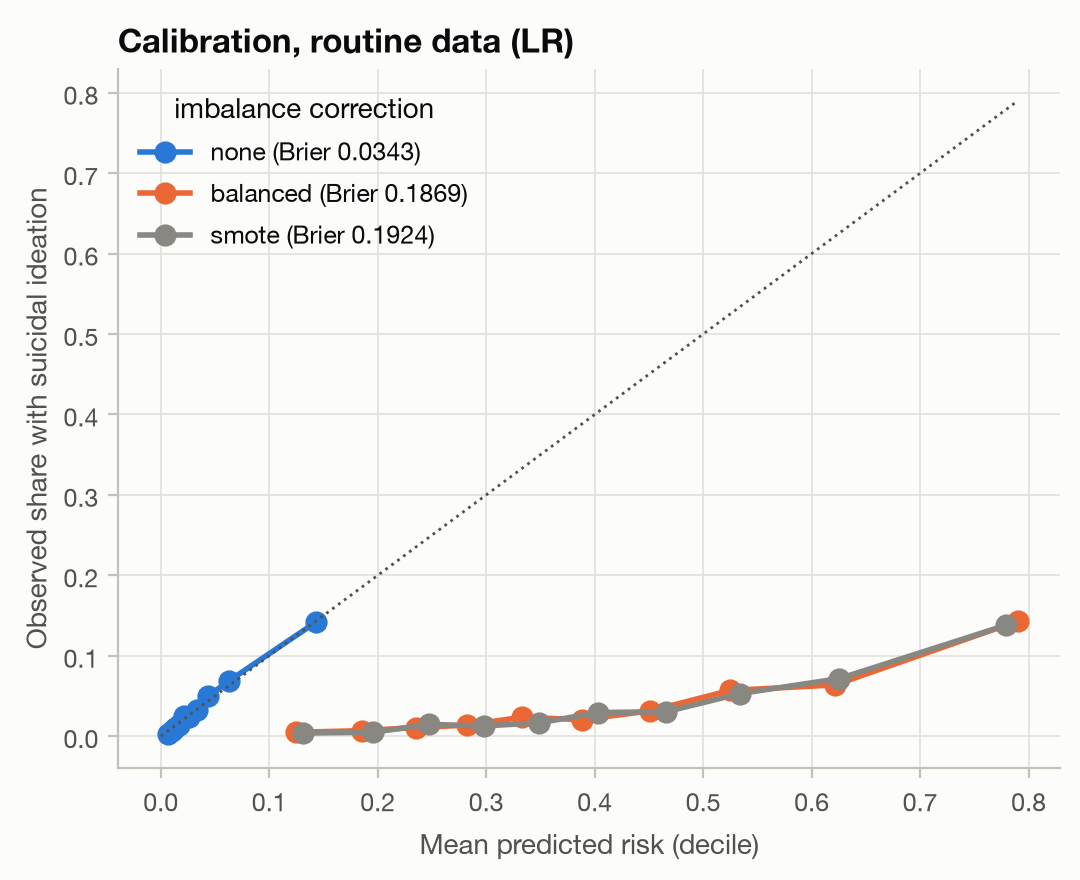

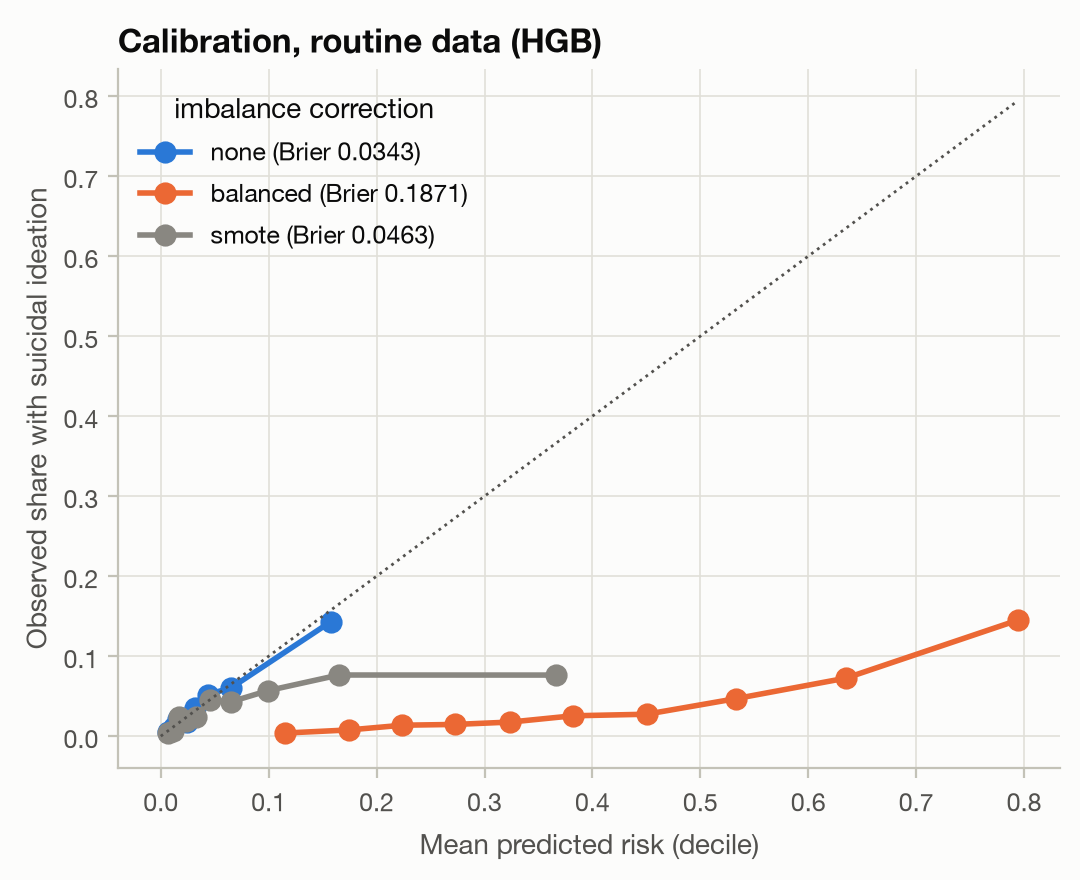

In [5]:
display(Image(REPORT_FIGURES / "10_calibration_imbalance_lr.png", width=480))
display(Image(REPORT_FIGURES / "11_calibration_imbalance_hgb.png", width=480))

### Main question: adults the depression screen misses

,screen,model,n,cases,prevalence,pr_auc,pr_auc_ci_low,pr_auc_ci_high,roc_auc,pr_auc_over_prevalence
0,PHQ9 < 10,routine,9328,128,0.014,0.029,0.022,0.044,0.671,2.145
1,PHQ9 < 10,routine (trained on screen-negative),9328,128,0.014,0.026,0.020,0.039,0.660,1.929
2,PHQ9 < 10,PHQ-8,9328,128,0.014,0.042,0.032,0.053,0.806,3.077
3,PHQ9 < 10,routine + PHQ-8,9328,128,0.014,0.049,0.037,0.074,0.808,3.587
4,PHQ9 < 10,demographics,9328,128,0.014,0.013,0.011,0.017,0.483,0.970
5,PHQ8 < 10,routine,9353,153,0.016,0.038,0.029,0.054,0.693,2.313
6,PHQ8 < 10,routine (trained on screen-negative),9353,153,0.016,0.035,0.026,0.048,0.684,2.115
7,PHQ8 < 10,PHQ-8,9353,153,0.016,0.067,0.052,0.086,0.835,4.090
8,PHQ8 < 10,routine + PHQ-8,9353,153,0.016,0.086,0.064,0.125,0.836,5.279
9,PHQ8 < 10,demographics,9353,153,0.016,0.017,0.014,0.024,0.497,1.055


,comparison,metric,estimate,ci_low,ci_high
0,routine + PHQ-8 - PHQ-8 among PHQ9 < 10,pr_auc,0.007,-8.000e-04,0.027
1,routine + PHQ-8 - PHQ-8 among PHQ8 < 10,pr_auc,0.019,5.600e-03,0.047


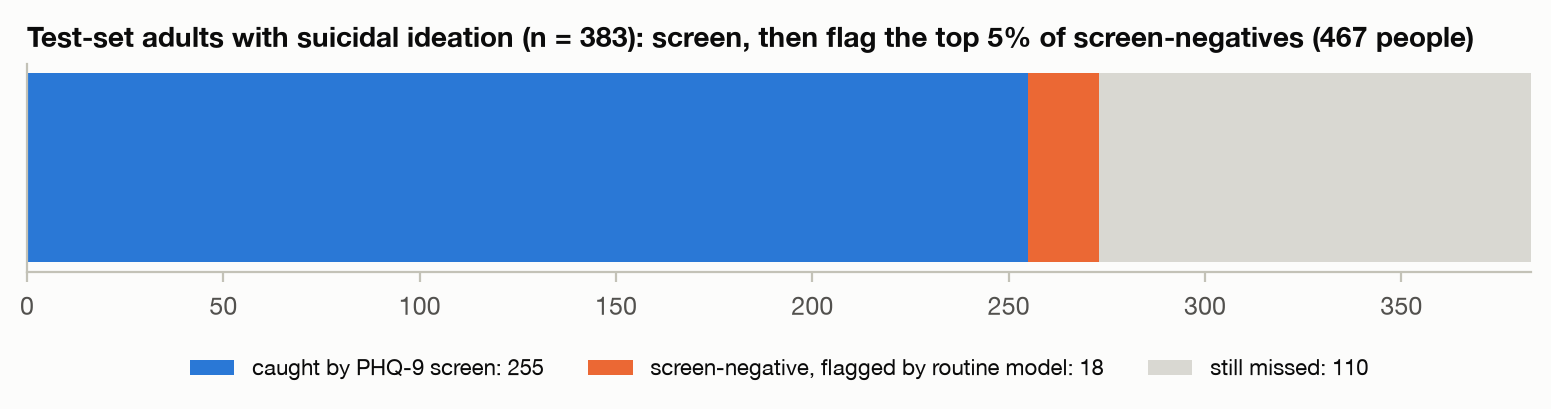

,0,1,2,3
screen,PHQ9 >= 10,PHQ9 >= 10,PHQ8 >= 10,PHQ8 >= 10
model,routine|hgb|none,routine_phq8|lr|none,routine|hgb|none,routine_phq8|lr|none
test_adults,10202,10202,10202,10202
test_cases,383,383,383,383
screen_positive,874,874,849,849
cases_caught_by_screen,255,255,230,230
cases_missed_by_screen,128,128,153,153
screen_negative_flagged_top5,467,467,468,468
missed_cases_caught_by_model,18,29,24,47
share_of_missed_cases_caught,0.141,0.227,0.157,0.307


In [6]:
display(t("step5_screen_negative.csv")[["screen", "model", "n", "cases", "prevalence", "pr_auc", "pr_auc_ci_low",
                                          "pr_auc_ci_high", "roc_auc", "pr_auc_over_prevalence"]])
display(t("step5_screen_negative_differences.csv"))
display(Image(REPORT_FIGURES / "13_screen_then_flag.png", width=700))
t("step5_screen_then_flag.csv").T

### Fairness (H4)

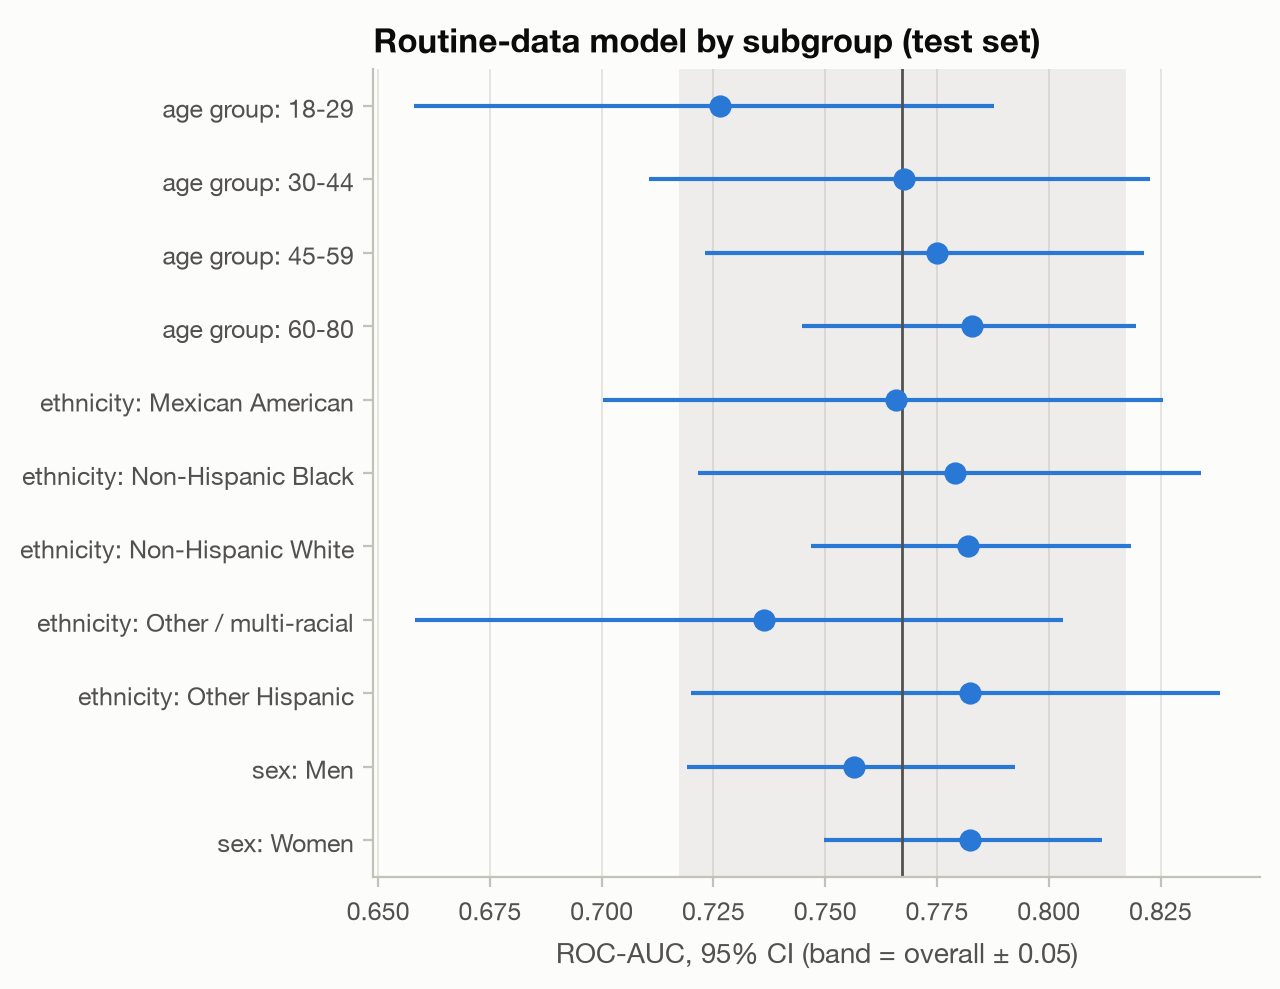

,attribute,group,n,cases,prevalence,roc_auc,roc_auc_ci_low,roc_auc_ci_high,pr_auc,pr_auc_ci_low,pr_auc_ci_high,pr_auc_over_prevalence,pr_auc_over_prevalence_ci_low,pr_auc_over_prevalence_ci_high,recall_at_global_top5,recall_at_global_top5_ci_low,recall_at_global_top5_ci_high
0,age group,18-29,2024,80,0.040,0.726,0.658,0.788,0.163,0.098,0.243,4.118,2.652,6.295,0.150,0.072,0.230
1,age group,30-44,2324,76,0.033,0.767,0.711,0.823,0.170,0.105,0.256,5.197,3.335,8.059,0.289,0.184,0.394
2,age group,45-59,2367,92,0.039,0.775,0.723,0.821,0.149,0.104,0.224,3.831,2.814,5.758,0.326,0.239,0.426
3,age group,60-80,3487,135,0.039,0.783,0.745,0.820,0.138,0.103,0.191,3.554,2.830,4.918,0.230,0.158,0.301
4,ethnicity,Mexican American,1628,67,0.041,0.766,0.700,0.826,0.160,0.105,0.252,3.878,2.753,6.113,0.224,0.129,0.323
5,ethnicity,Non-Hispanic Black,2272,62,0.027,0.779,0.722,0.834,0.133,0.075,0.222,4.866,2.992,8.211,0.274,0.160,0.386
6,ethnicity,Non-Hispanic White,3502,134,0.038,0.782,0.747,0.818,0.149,0.106,0.211,3.898,2.932,5.521,0.209,0.144,0.278
7,ethnicity,Other / multi-racial,1683,62,0.037,0.736,0.658,0.803,0.135,0.086,0.221,3.670,2.497,5.975,0.161,0.077,0.268
8,ethnicity,Other Hispanic,1117,58,0.052,0.782,0.720,0.838,0.188,0.124,0.279,3.612,2.557,5.510,0.431,0.306,0.565
9,sex,Men,4986,198,0.040,0.756,0.719,0.792,0.155,0.119,0.207,3.899,3.123,5.191,0.232,0.179,0.293


In [7]:
display(Image(REPORT_FIGURES / "12_fairness_roc_auc.png", width=600))
t("step5_fairness_routine.csv")

### Sensitivity: stricter outcome

In [8]:
t("step5_sensitivity_si_strict.csv")

,model,outcome,cases,prevalence,pr_auc,roc_auc,brier,recall_top5,precision_top5
0,phq8|lr|none,si_strict,121,0.012,0.204,0.932,0.010,0.686,0.162
1,routine|hgb|none,si_strict,121,0.012,0.046,0.767,0.012,0.281,0.067
2,routine_phq8|lr|none,si_strict,121,0.012,0.210,0.932,0.010,0.703,0.166


## Step 6 — explainability

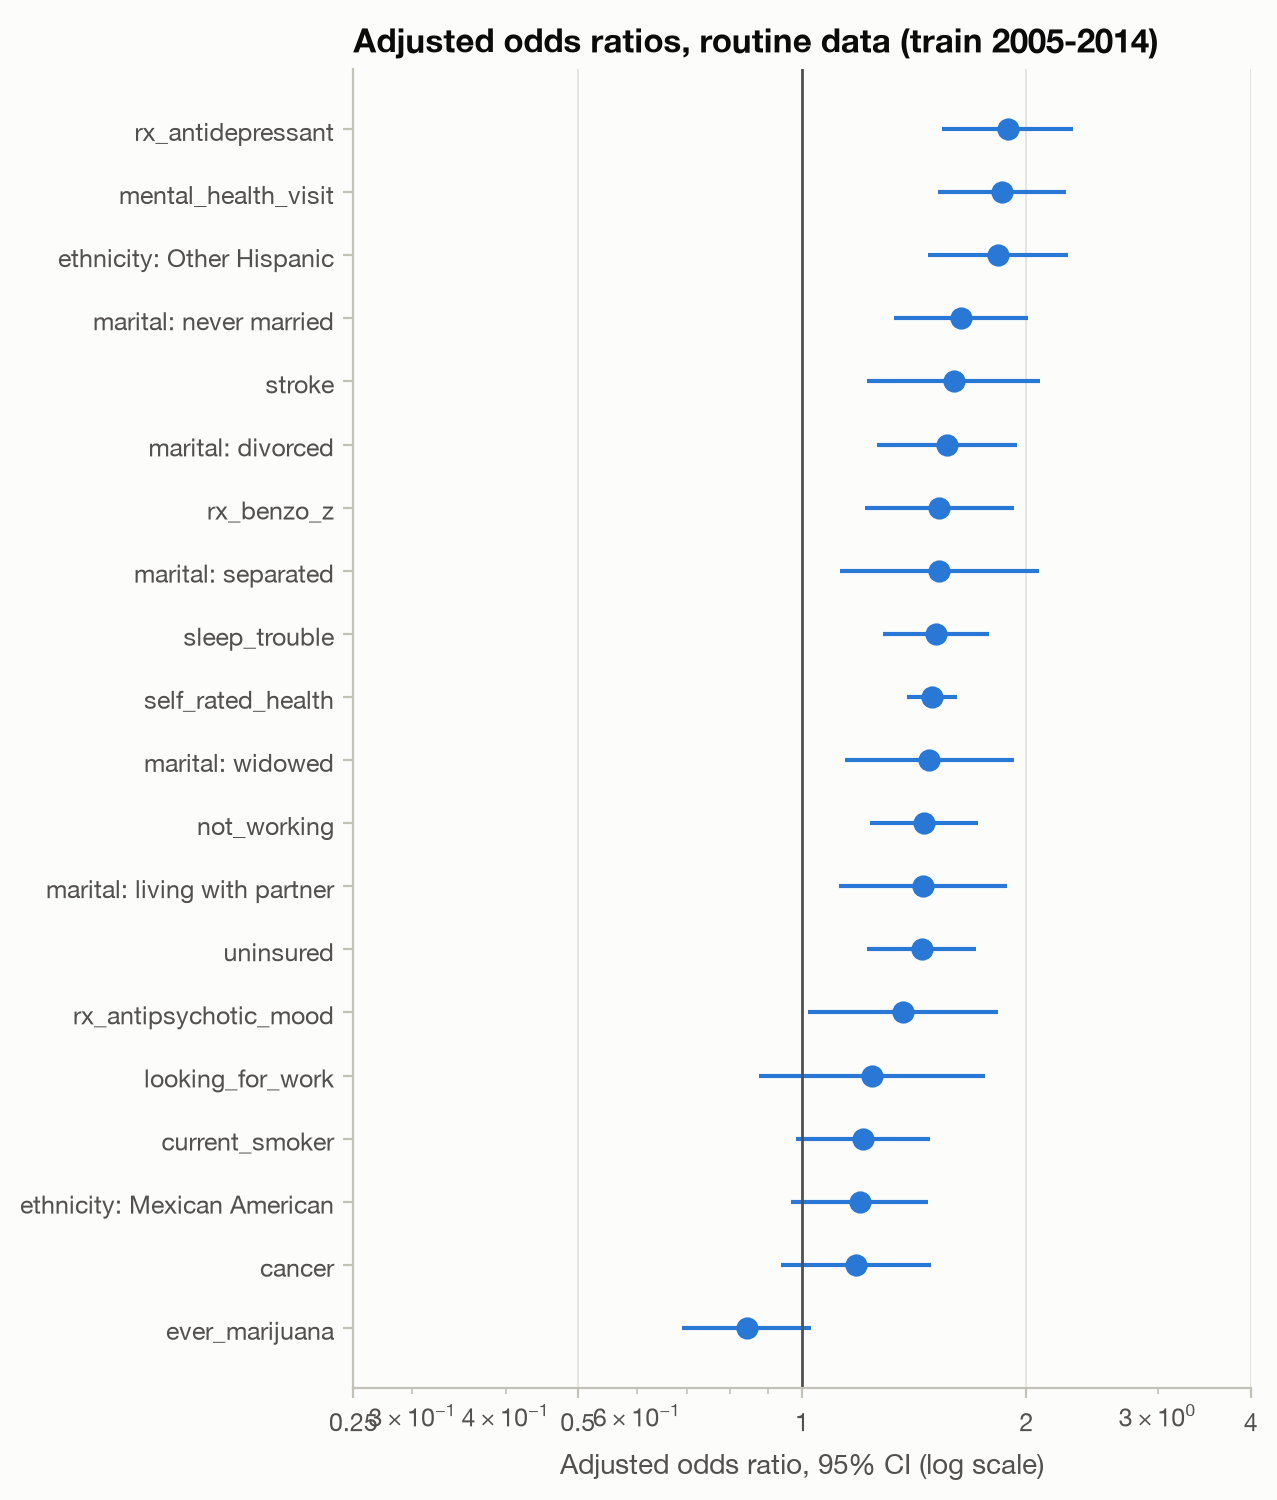

,feature,unit,odds_ratio,ci_low,ci_high,p_value
0,missing: arthritis,NaN,2.167,1.274,3.686,4.300e-03
1,rx_antidepressant,NaN,1.887,1.541,2.311,0.000e+00
2,mental_health_visit,NaN,1.855,1.522,2.260,0.000e+00
3,ethnicity: Other Hispanic,NaN,1.833,1.477,2.276,0.000e+00
4,marital: never married,NaN,1.635,1.330,2.009,0.000e+00
5,stroke,NaN,1.598,1.222,2.088,6.000e-04
6,marital: divorced,NaN,1.565,1.262,1.942,0.000e+00
7,rx_benzo_z,NaN,1.529,1.213,1.926,3.000e-04
8,marital: separated,NaN,1.528,1.123,2.080,7.000e-03
9,sleep_trouble,NaN,1.511,1.282,1.780,0.000e+00


In [9]:
display(Image(REPORT_FIGURES / "14_odds_ratios.png", width=600))
t("step6_odds_ratios.csv")

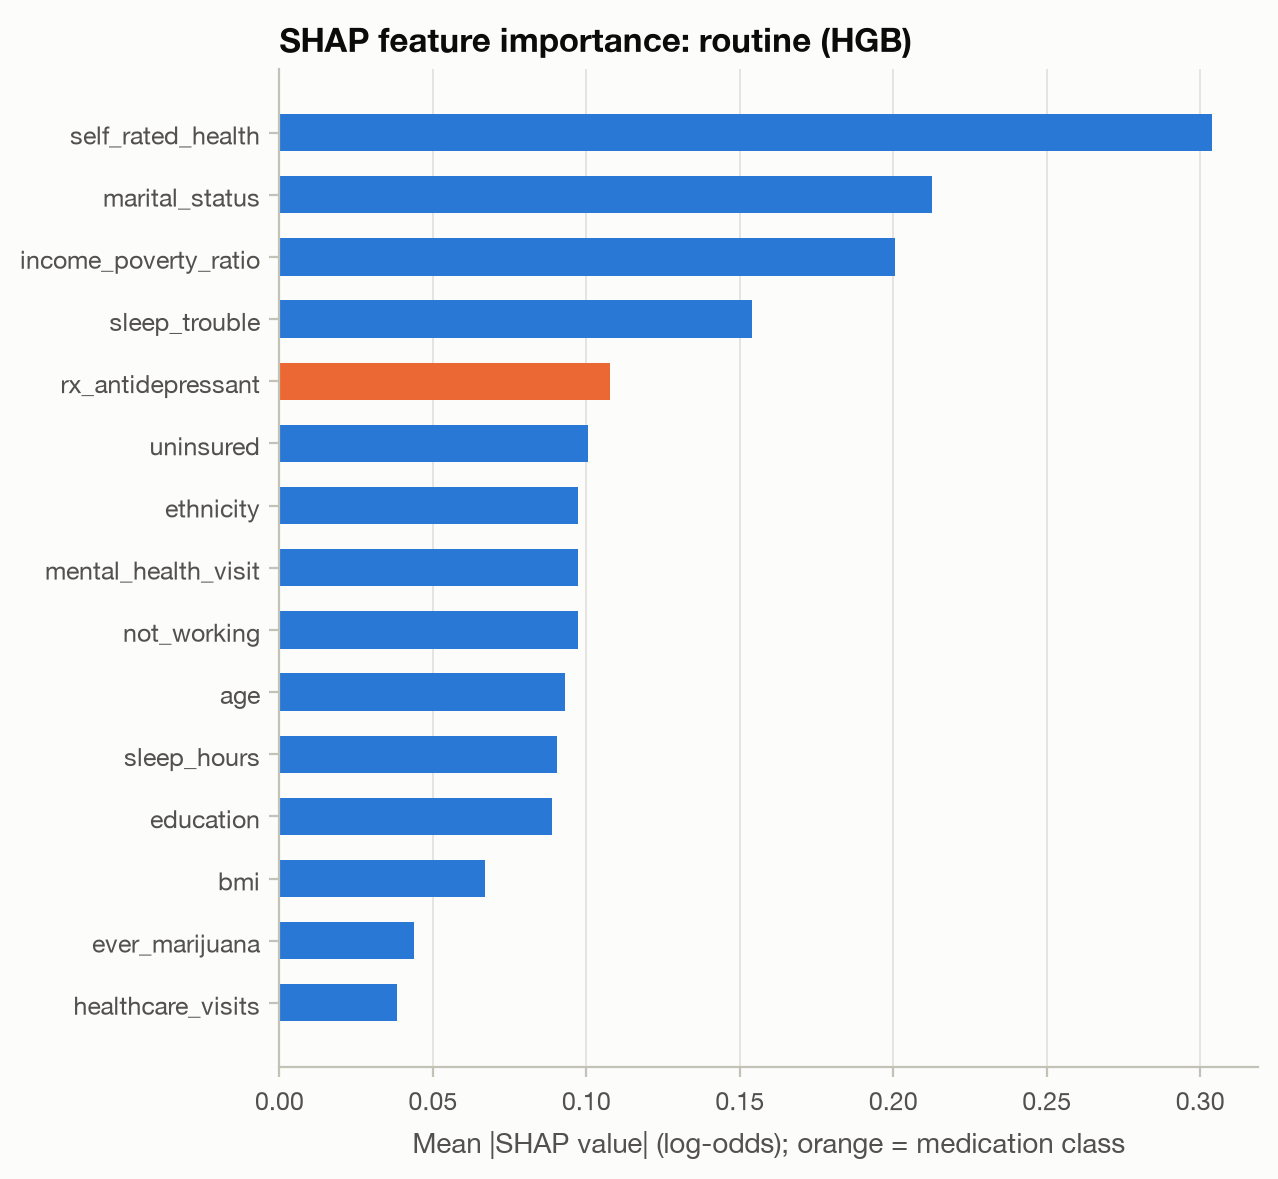

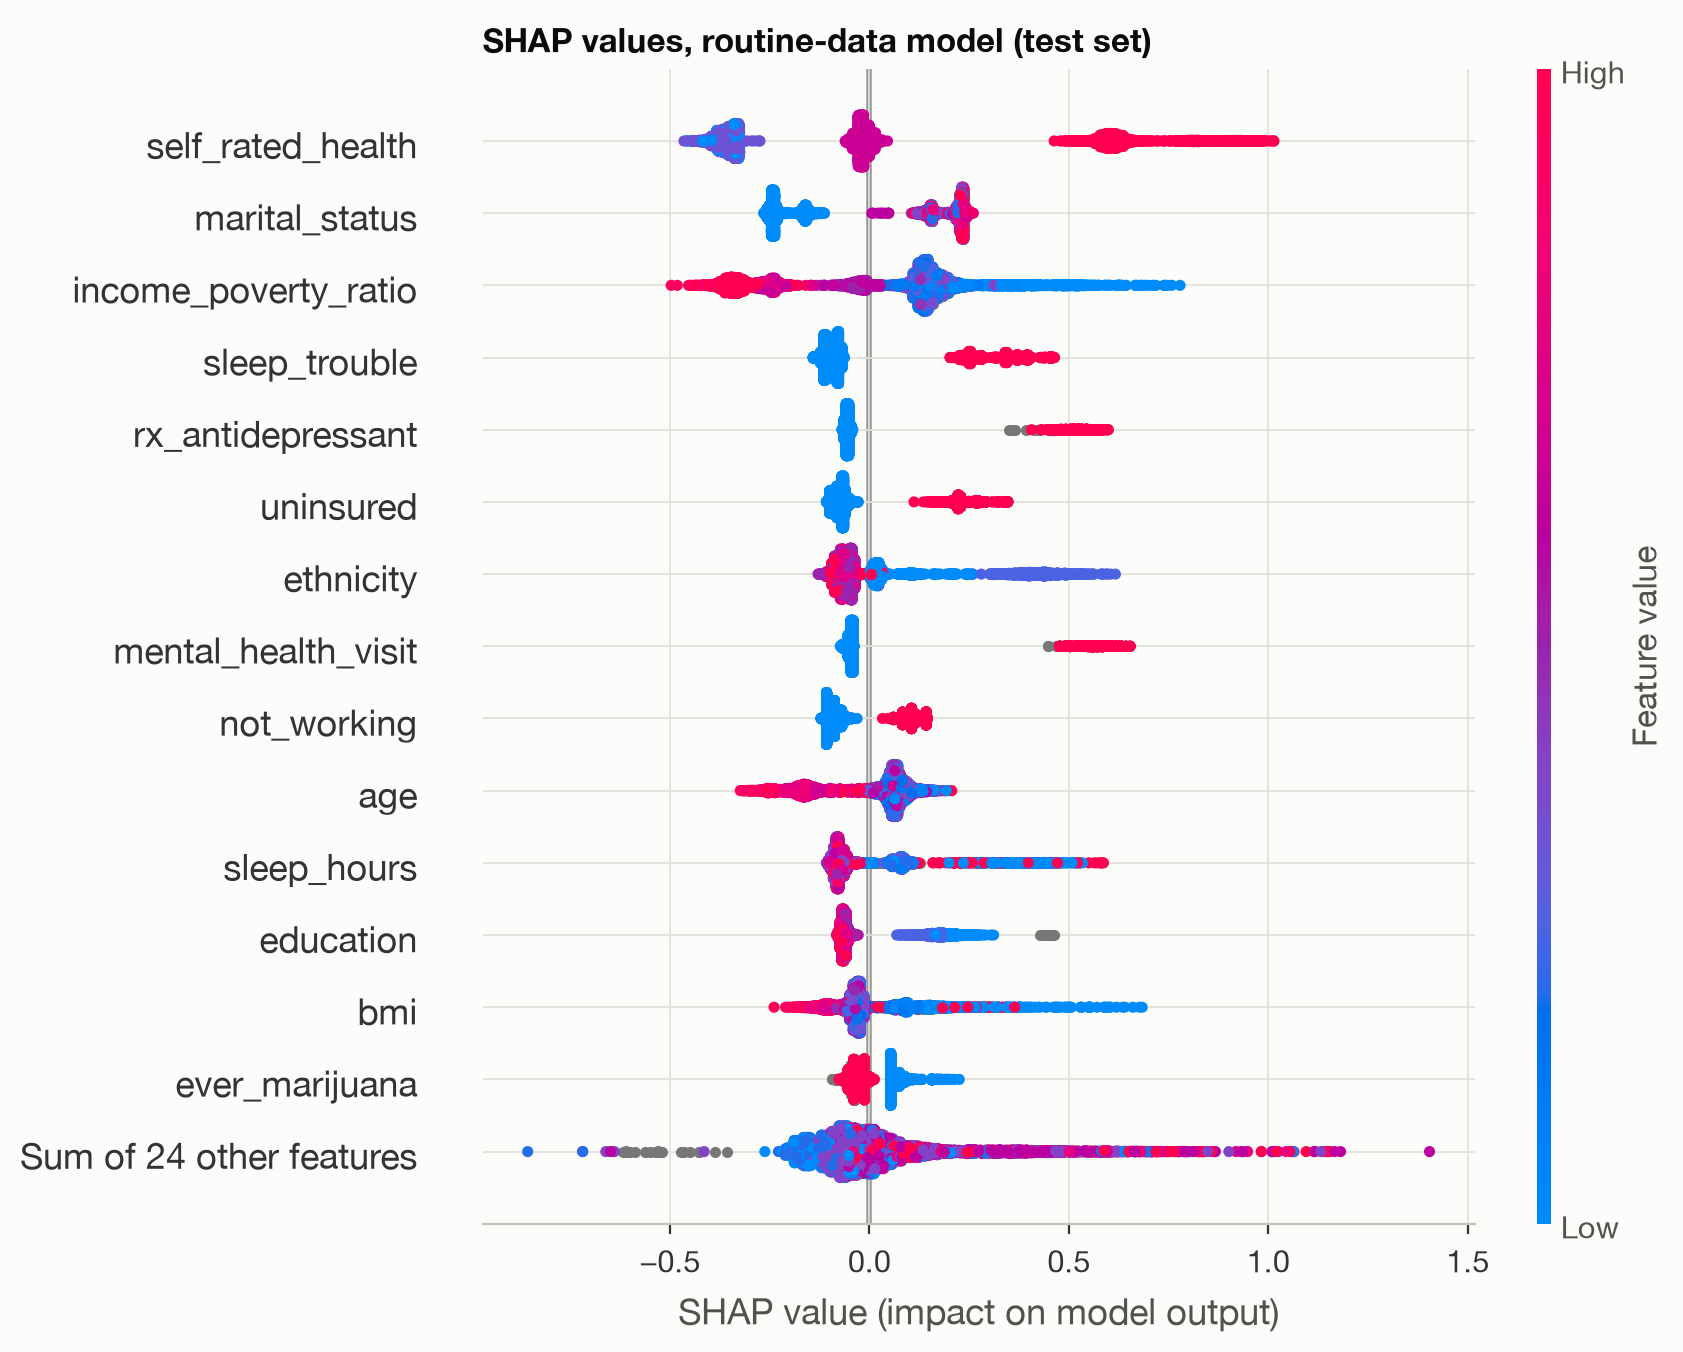

,feature,mean_abs_shap,direction_corr
0,self_rated_health,0.304,0.932
1,marital_status,0.213,NaN
2,income_poverty_ratio,0.201,-0.945
3,sleep_trouble,0.154,0.981
4,rx_antidepressant,0.108,0.998
5,uninsured,0.100,0.989
6,ethnicity,0.097,NaN
7,mental_health_visit,0.097,0.998
8,not_working,0.097,0.984
9,age,0.093,-0.659


In [10]:
display(Image(REPORT_FIGURES / "15_shap_importance_routine.png", width=600))
display(Image(REPORT_FIGURES / "16_shap_beeswarm_routine.png", width=600))
t("step6_shap_importance_routine.csv").head(15)

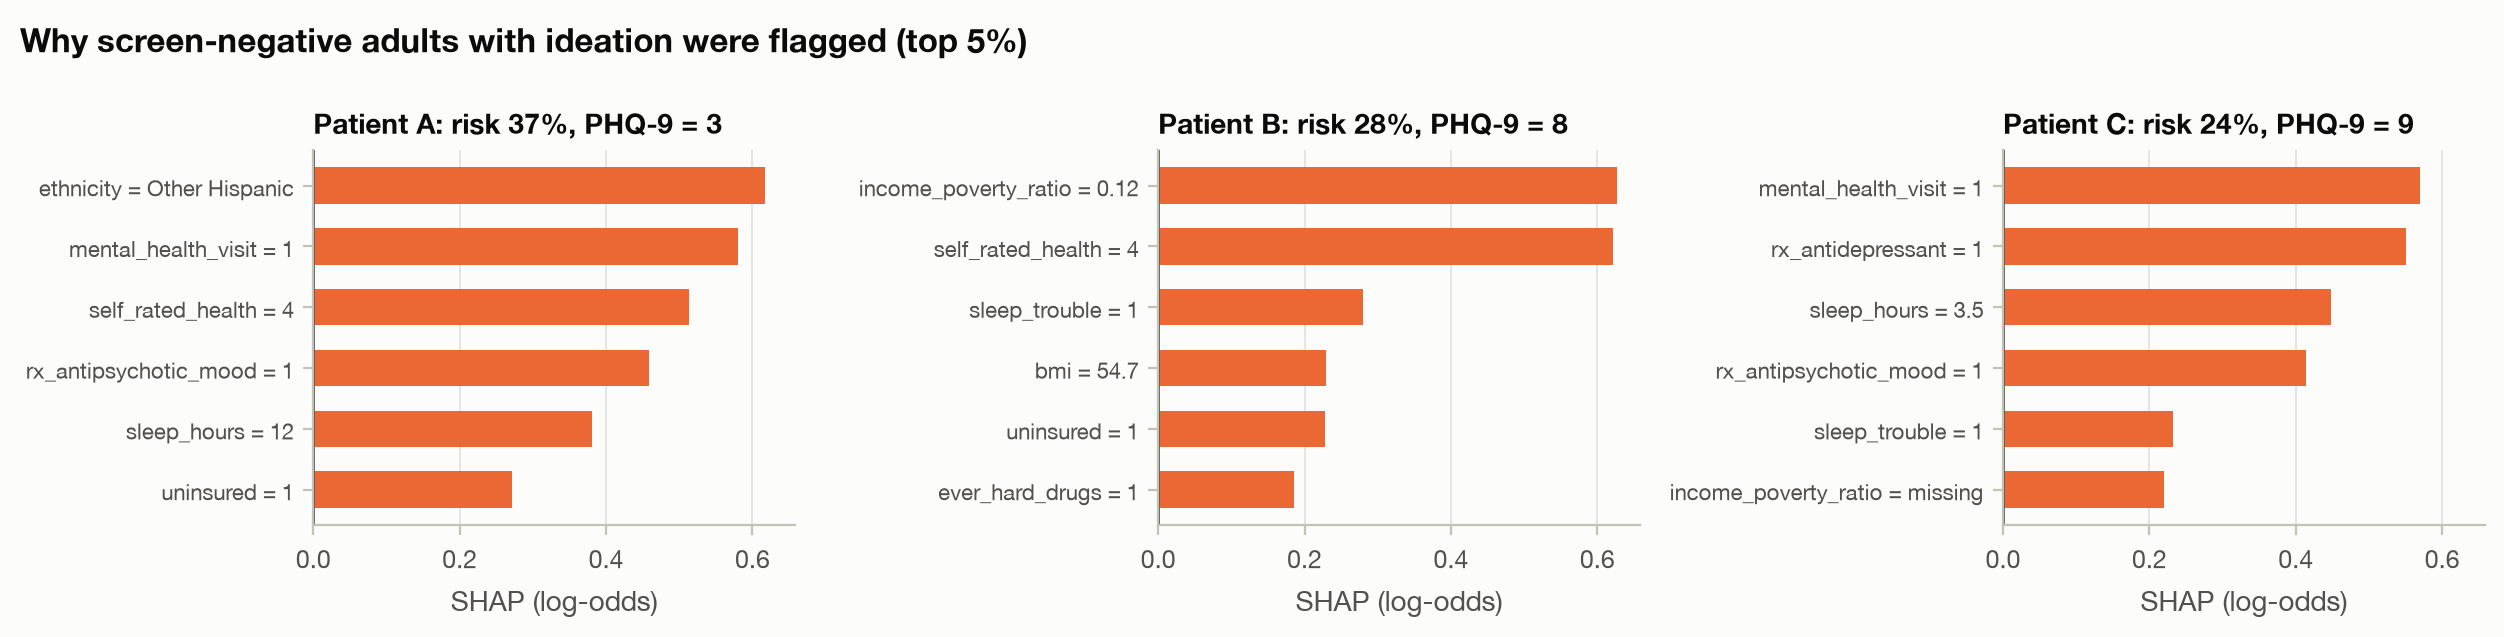

,patient,predicted_risk,phq9_score,feature,value,shap_log_odds
0,Patient A,0.366,3.0,ethnicity,2.00,0.617
1,Patient A,0.366,3.0,mental_health_visit,1.00,0.580
2,Patient A,0.366,3.0,self_rated_health,4.00,0.513
3,Patient A,0.366,3.0,rx_antipsychotic_mood,1.00,0.459
4,Patient A,0.366,3.0,sleep_hours,12.00,0.381
5,Patient A,0.366,3.0,uninsured,1.00,0.272
6,Patient B,0.281,8.0,income_poverty_ratio,0.12,0.627
7,Patient B,0.281,8.0,self_rated_health,4.00,0.622
8,Patient B,0.281,8.0,sleep_trouble,1.00,0.280
9,Patient B,0.281,8.0,bmi,54.70,0.229


In [11]:
display(Image(REPORT_FIGURES / "17_patient_explanations.png", width=900))
t("step6_patient_explanations.csv")